# Projeto Aplicado I — Itaú Unibanco
## Análise exploratória das operações de crédito e da inadimplência (2024–2026)

**Pergunta de pesquisa:** Como a evolução do indicador selecionado de operações de crédito se relacionou com a evolução da inadimplência entre 2024 e 2026?

Este notebook realiza uma análise exploratória com dados públicos da área de Relações com Investidores do Itaú Unibanco. A planilha utilizada corresponde às Séries Históricas do 2º trimestre de 2026.

**Importante:** o indicador de crédito usado aqui tem o nome específico apresentado na planilha — operações de crédito com garantias financeiras prestadas e títulos privados. Ele não deve ser descrito automaticamente como toda a carteira de crédito do banco.


## 1. Bibliotecas e leitura da base

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Procura o arquivo na pasta dados do projeto.
candidatos = [
    Path("../dados/Planilha_Series_Historicas_2T26.xlsx"),
    Path("dados/Planilha_Series_Historicas_2T26.xlsx"),
    Path("../../dados/Planilha_Series_Historicas_2T26.xlsx"),
]
arquivo = next((p for p in candidatos if p.exists()), None)
if arquivo is None:
    raise FileNotFoundError(
        "Não encontrei a planilha. Coloque Planilha_Series_Historicas_2T26.xlsx na pasta dados."
    )

sumario = pd.read_excel(arquivo, sheet_name="Sumário_PRO FORMA", header=None)
print("Dimensão da aba Sumário_PRO FORMA:", sumario.shape)
display(sumario.head(5))


Dimensão da aba Sumário_PRO FORMA: (56, 13)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Sumário Executivo (R$ mil...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,R$ milhões (exceto onde indicado)
1,Destaques,NaN,NaN,1T24,2T24,3T24,4T24,1T25,2T25,3T25,4T25,1T26,2T26
2,Demonstração do Resultado do Período,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Resultado Recorrente Gerencial,NaN,9770.983671,10072.375121,10675.140598,10884.120315,11128.122268,11508.326478,11876.306373,12317.167241,12282.114877,12406.686278
4,NaN,Produto Bancário (1),NaN,40619.486477,42155.003433,43052.075479,44552.680165,44793.344634,45828.461779,46604.931388,47617.451331,46822.259885,47984.926909


## 2. Extração dos indicadores selecionados

In [9]:
# Os períodos estão na segunda linha da planilha e os valores nas colunas D:M.
periodos = sumario.iloc[1, 3:13].astype(str).tolist()
rotulos = sumario.iloc[:, 1].astype(str)

# Inadimplência de 90 dias — total
linhas_npl = sumario[rotulos.str.contains(
    "Índice de Inadimplência", case=False, regex=False, na=False
)]
linha_npl = linhas_npl[
    linhas_npl.iloc[:, 1].astype(str).str.contains(
        "Total", case=False, regex=False, na=False
    )
].iloc[0]
valores_npl = pd.to_numeric(linha_npl.iloc[3:13], errors="coerce")

tabela_npl = pd.DataFrame({
    "Trimestre": periodos,
    "Inadimplência (%)": valores_npl.values * 100
})

# Indicador de operações de crédito com garantias financeiras prestadas e títulos privados
mascara_credito = rotulos.str.contains(
    "Total de Operações de Crédito com Garantias Financeiras Prestadas e Títulos Privados",
    case=False, regex=False, na=False
)
linha_credito = sumario[mascara_credito].iloc[0]
valores_credito = pd.to_numeric(linha_credito.iloc[3:13], errors="coerce")

tabela_credito = pd.DataFrame({
    "Trimestre": periodos,
    "Operações de crédito (R$ milhões)": valores_credito.values
})

display(tabela_npl)
display(tabela_credito)


,Trimestre,Inadimplência (%)
0,1T24,2.700000
1,2T24,2.600000
2,3T24,2.500000
3,4T24,1.957214
4,1T25,1.905197
5,2T25,1.906960
6,3T25,1.881074
7,4T25,1.890184
8,1T26,1.902463
9,2T26,1.948798


,Trimestre,Operações de crédito (R$ milhões)
0,1T24,1.222333e+06
1,2T24,1.294695e+06
2,3T24,1.318082e+06
3,4T24,1.406357e+06
4,1T25,1.383097e+06
5,2T25,1.389076e+06
6,3T25,1.402039e+06
7,4T25,1.490816e+06
8,1T26,1.482699e+06
9,2T26,1.522385e+06


## 3. Estatísticas descritivas e qualidade dos dados

In [10]:
serie = tabela_npl["Inadimplência (%)"]
estatisticas = pd.DataFrame({
    "Medida": ["Quantidade de observações", "Média (%)", "Mediana (%)",
               "Mínimo (%)", "Máximo (%)", "Desvio-padrão (p.p.)",
               "Variância (p.p.²)", "Valores ausentes"],
    "Resultado": [
        serie.count(), serie.mean(), serie.median(), serie.min(), serie.max(),
        serie.std(), serie.var(), serie.isna().sum()
    ]
})
display(estatisticas.round(4))

print("Resumo das operações de crédito (R$ milhões):")
display(tabela_credito["Operações de crédito (R$ milhões)"].describe().round(2))


,Medida,Resultado
0,Quantidade de observações,10.0000
1,Média (%),2.1192
2,Mediana (%),1.9279
3,Mínimo (%),1.8811
4,Máximo (%),2.7000
5,Desvio-padrão (p.p.),0.3359
6,Variância (p.p.²),0.1129
7,Valores ausentes,0.0000


Resumo das operações de crédito (R$ milhões):


count         10.00
mean     1391158.00
std        93747.86
min      1222333.04
25%      1334335.82
50%      1395557.68
75%      1463613.67
max      1522384.99
Name: Operações de crédito (R$ milhões), dtype: float64

## 4. Gráfico da inadimplência

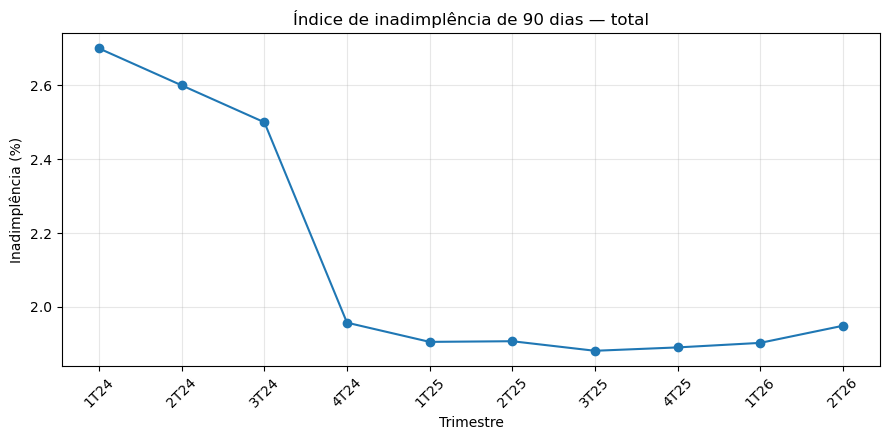

In [11]:
plt.figure(figsize=(9, 4.5))
plt.plot(tabela_npl["Trimestre"], tabela_npl["Inadimplência (%)"], marker="o")
plt.title("Índice de inadimplência de 90 dias — total")
plt.xlabel("Trimestre")
plt.ylabel("Inadimplência (%)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Gráfico das operações de crédito

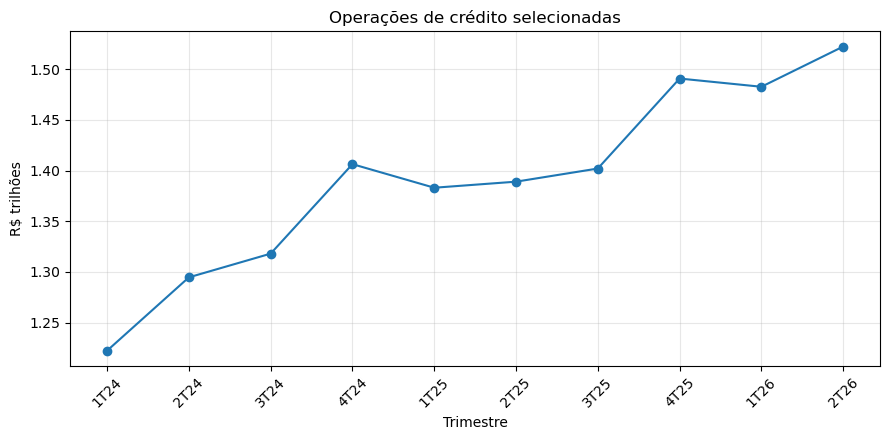

In [12]:
plt.figure(figsize=(9, 4.5))
plt.plot(tabela_credito["Trimestre"],
         tabela_credito["Operações de crédito (R$ milhões)"] / 1_000_000,
         marker="o")
plt.title("Operações de crédito selecionadas")
plt.xlabel("Trimestre")
plt.ylabel("R$ trilhões")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Comparação visual dos indicadores

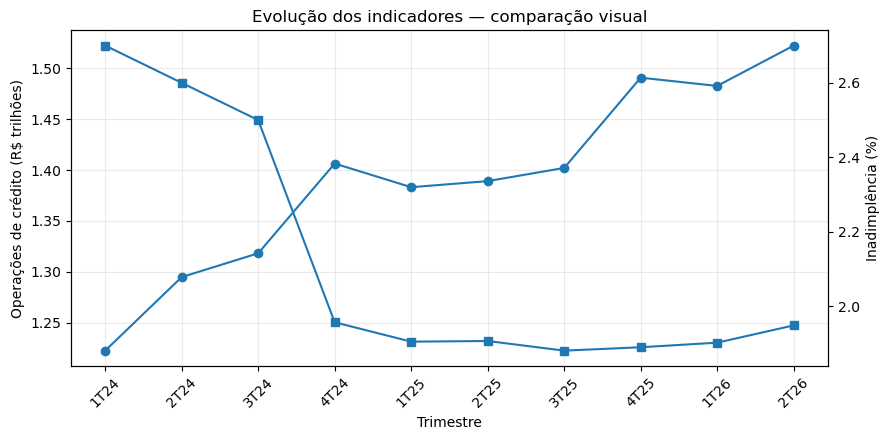

In [13]:
comparacao = pd.merge(tabela_credito, tabela_npl, on="Trimestre", how="inner").dropna()

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(comparacao["Trimestre"],
         comparacao["Operações de crédito (R$ milhões)"] / 1_000_000,
         marker="o")
ax1.set_xlabel("Trimestre")
ax1.set_ylabel("Operações de crédito (R$ trilhões)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(True, alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(comparacao["Trimestre"], comparacao["Inadimplência (%)"], marker="s")
ax2.set_ylabel("Inadimplência (%)")
plt.title("Evolução dos indicadores — comparação visual")
fig.tight_layout()
plt.show()


## 7. Variação percentual e correlação

In [14]:
credito_inicio = comparacao["Operações de crédito (R$ milhões)"].iloc[0]
credito_fim = comparacao["Operações de crédito (R$ milhões)"].iloc[-1]
variacao_credito = (credito_fim / credito_inicio - 1) * 100

npl_inicio = comparacao["Inadimplência (%)"].iloc[0]
npl_fim = comparacao["Inadimplência (%)"].iloc[-1]
variacao_npl_pp = npl_fim - npl_inicio

correlacao = comparacao[
    ["Operações de crédito (R$ milhões)", "Inadimplência (%)"]
].corr().iloc[0, 1]

print(f"Trimestres analisados: {len(comparacao)}")
print(f"Variação das operações de crédito: {variacao_credito:.2f}%")
print(f"Inadimplência inicial: {npl_inicio:.3f}%")
print(f"Inadimplência final: {npl_fim:.3f}%")
print(f"Variação da inadimplência: {variacao_npl_pp:.3f} ponto percentual")
print(f"Correlação de Pearson: {correlacao:.4f}")


Trimestres analisados: 10
Variação das operações de crédito: 24.55%
Inadimplência inicial: 2.700%
Inadimplência final: 1.949%
Variação da inadimplência: -0.751 ponto percentual
Correlação de Pearson: -0.8473


## 8. Interpretação dos resultados

O indicador selecionado de operações de crédito aumentou aproximadamente 24,55% entre 1T24 e 2T26. No mesmo intervalo, o índice de inadimplência de 90 dias caiu de 2,700% para aproximadamente 1,949%, uma redução de 0,751 ponto percentual.

A correlação de Pearson calculada para os dez trimestres foi de aproximadamente -0,8473, indicando associação linear negativa forte nesta amostra. Esse resultado não demonstra causalidade: não é possível concluir que a expansão do crédito provocou a queda da inadimplência. Outros fatores podem influenciar os indicadores.

A interpretação também deve considerar as observações da própria planilha sobre alterações de classificação e composição dos dados, incluindo mudanças a partir de 1T25. A análise é exploratória e não deve ser apresentada como previsão ou prova de causa e efeito.

## Fonte

Itaú Unibanco — Relações com Investidores, Planilha de Séries Históricas referente ao 2º trimestre de 2026.  
https://www.itau.com.br/relacoes-com-investidores/resultados-e-relatorios/central-de-resultados/
